In [4]:
import pandas as pd
from statsmodels.stats.inter_rater import fleiss_kappa
import plotly.graph_objects as go
import matplotlib.pyplot as plt

### Data prep

In [5]:
df = pd.read_csv('merged_annotations.csv')

In [6]:
df.head()

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June...,0,none,none,none
1,I don't know what this man wrote here but I ca...,krajisnik_Public_Transcript_of_Hearing_09_June...,1,agency,agency,agency
2,And the man here says that the political leade...,krajisnik_Public_Transcript_of_Hearing_09_June...,2,none,none,none
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June...,3,none,none,none
4,I remember there was a quarrel and I said to t...,krajisnik_Public_Transcript_of_Hearing_09_June...,4,agency,agency,agency


In [7]:
def normalize_annotations(df, columns):
    for col in columns:
        df[col] = df[col].astype(str).str.strip().str.lower()
    return df

In [8]:
df = normalize_annotations(
    df,
    ["label_lisa", "label_julian", "label_thea"]
)

In [9]:
for col in ['label_lisa', 'label_julian', 'label_thea']:
    print(f"{col}: dtype = {df[col].dtype}, unique = {df[col].unique()}")

label_lisa: dtype = object, unique = ['none' 'agency' 'externalization']
label_julian: dtype = object, unique = ['none' 'agency' 'externalization']
label_thea: dtype = object, unique = ['none' 'agency' 'externalization' 'nan']


In [10]:
df["label_thea"] = df["label_thea"].replace("nan", "none")

In [11]:
df['token_count'] = df['text'].apply(lambda x: len(str(x).split()))


In [12]:
min_tokens_per_sentence = df['token_count'].min()
average_tokens_per_sentence = df['token_count'].mean()
max_tokens_per_sentence = df['token_count'].max()

### Rows with least amount of tokens in the text

In [13]:
print(f"Average number of tokens per sentence: {min_tokens_per_sentence}")
print(f"Average number of tokens per sentence: {average_tokens_per_sentence}")
print(f"Average number of tokens per sentence: {max_tokens_per_sentence}")

Average number of tokens per sentence: 1
Average number of tokens per sentence: 20.861774744027304
Average number of tokens per sentence: 182


In [14]:
sorted_df = df.sort_values(by='token_count')


### Rows with least amount of tokens in the text

In [15]:
lowest_token_count_rows = sorted_df.head(7)
lowest_token_count_rows

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June...,0,none,none,none,1
435,Yes.,seselj_Public_Transcript_of_Hearing_22_January...,0,none,none,none,1
301,No.,krstic_Public_Transcript_of_Hearing_October_19...,0,none,none,none,1
21,227.,prlic_and_others_Public_Transcript_of_Hearing_...,1,none,none,none,1
130,No.,vasiljevic_Public_Transcript_of_Hearing_Octobe...,0,none,none,none,1
99,Yes.,simic_et_al_Public_Transcript_of_Hearing_8_May...,0,none,none,none,1
160,Fine.,milosevic_02-54_Public_Transcript_of_Hearing_J...,0,none,none,none,1


### Rows with most amount of tokens in the text

In [16]:
highest_token_count_rows = sorted_df.tail(7)
highest_token_count_rows

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
413,"But be that as it may, we stayed because we ho...",krnojelac_Public_Transcript_of_Hearing_June_25...,4,agency,agency,externalization,74
37,Do you agree that this is my order to the Main...,karadzic_and_mladic_95-5_18_Public_Transcript_...,0,none,agency,agency,74
171,I have already said that he had a diametricall...,blaskic_Public_Transcript_of_Hearing_05_May_19...,0,none,none,none,82
146,And this is why a certain number of Serbs was ...,simic_et_al_Public_Transcript_of_Hearing_15_Ma...,1,none,externalization,externalization,83
98,"I arrived in the evening, and I was immediatel...",blaskic_Public_Transcript_of_Hearing_08_April_...,0,none,externalization,none,83
432,Our lines in the area of Gornji Vakuf are in d...,prlic_and_others_Public_Transcript_of_Hearing_...,2,agency,externalization,agency,110
145,I have heard something about it when they arri...,simic_et_al_Public_Transcript_of_Hearing_15_Ma...,0,none,externalization,externalization,182


In [17]:
def find_complete_disagreement(df, ann1, ann2, ann3):
    return df[
        (df[ann1] != df[ann2]) &
        (df[ann2] != df[ann3]) &
        (df[ann1] != df[ann3])
    ]

In [18]:
complete_disagreement = find_complete_disagreement(
    df,
    "label_lisa",
    "label_julian",
    "label_thea"
)

In [19]:
print(type(complete_disagreement))
print(complete_disagreement.shape)
print(complete_disagreement.empty)

<class 'pandas.core.frame.DataFrame'>
(11, 7)
False


### Rows with complete disagreement in annotation (11 rows)

In [20]:
complete_disagreement[
    ["text", "label_lisa", "label_julian", "label_thea"]
]

,text,label_lisa,label_julian,label_thea
43,I never received any order from the head of th...,agency,none,externalization
137,"But I say here, since I was quoted out of cont...",agency,externalization,none
140,And then I go on to say that is how it always ...,agency,externalization,none
150,"I know that for certain, because the ethnic re...",externalization,agency,none
151,"Now, as far as this goal is concerned, it's ex...",externalization,agency,none
196,"With your permission, may I say that I never h...",agency,none,externalization
228,"And then I say, All right, that's it.",agency,none,externalization
279,This order was written following the press con...,externalization,agency,none
313,"That is what I am saying now, but in those day...",none,agency,externalization
398,It's possible that I attended some meeting of ...,agency,none,externalization


In [21]:
complete_agreement = df[
    (df["label_lisa"] == df["label_julian"]) &
    (df["label_julian"] == df["label_thea"]) &
    (df["label_lisa"] == df["label_thea"])
]

In [22]:
pd.set_option('display.max_colwidth', None)  # Set to None to prevent truncation
pd.set_option('display.max_rows', None)  # Show all columns


### Rows with complete agreement (411 rows)

In [23]:
complete_agreement.head()

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,none,none,none,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,agency,agency,agency,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,none,none,none,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,none,none,none,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,agency,agency,agency,38


In [24]:
print(f"Nr of rows with complete agreement among annotators: {len(complete_agreement)} ({len(complete_agreement) / len(df):.2%})")


Nr of rows with complete agreement among annotators: 411 (70.14%)


### Distribution of annotations

In [25]:
label_cols = ["label_lisa", "label_julian", "label_thea"]

overall_counts = (
    df[label_cols]
    .stack()
    .value_counts()
    .to_dict()
)

print(overall_counts)

{'none': 1118, 'externalization': 401, 'agency': 239}


In [26]:
annotator_counts = {
    "lisa": df["label_lisa"].value_counts(),
    "julian": df["label_julian"].value_counts(),
    "thea": df["label_thea"].value_counts()
}

annotator_counts

{'lisa': label_lisa
 none               369
 externalization    124
 agency              93
 Name: count, dtype: int64,
 'julian': label_julian
 none               389
 externalization    122
 agency              75
 Name: count, dtype: int64,
 'thea': label_thea
 none               360
 externalization    155
 agency              71
 Name: count, dtype: int64}

In [27]:
print("Overall Counts:", overall_counts)
print("\nCounts Per Annotator:")
for annotator, counts in annotator_counts.items():
    print(f"{annotator.capitalize()} Counts:\n{counts}\n")


Overall Counts: {'none': 1118, 'externalization': 401, 'agency': 239}

Counts Per Annotator:
Lisa Counts:
label_lisa
none               369
externalization    124
agency              93
Name: count, dtype: int64

Julian Counts:
label_julian
none               389
externalization    122
agency              75
Name: count, dtype: int64

Thea Counts:
label_thea
none               360
externalization    155
agency              71
Name: count, dtype: int64



#### Plotting distribution of annotations per annotator

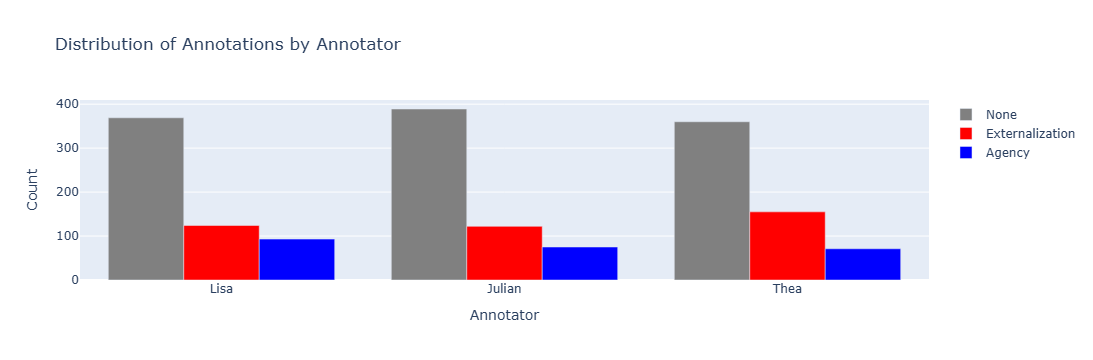

In [28]:
# Annotation categories
annotations = ["none", "externalization", "agency"]

# Count annotations for each annotator
lisa_counts = (
    df["label_lisa"]
    .value_counts()
    .reindex(annotations, fill_value=0)
)

julian_counts = (
    df["label_julian"]
    .value_counts()
    .reindex(annotations, fill_value=0)
)

thea_counts = (
    df["label_thea"]
    .value_counts()
    .reindex(annotations, fill_value=0)
)

# Colors
colors = {
    "none": "grey",
    "externalization": "red",
    "agency": "blue"
}

# Create figure
fig = go.Figure()

# None
fig.add_trace(go.Bar(
    x=["Lisa", "Julian", "Thea"],
    y=[
        lisa_counts["none"],
        julian_counts["none"],
        thea_counts["none"]
    ],
    name="None",
    marker_color=colors["none"]
))

# Externalization
fig.add_trace(go.Bar(
    x=["Lisa", "Julian", "Thea"],
    y=[
        lisa_counts["externalization"],
        julian_counts["externalization"],
        thea_counts["externalization"]
    ],
    name="Externalization",
    marker_color=colors["externalization"]
))

# Agency
fig.add_trace(go.Bar(
    x=["Lisa", "Julian", "Thea"],
    y=[
        lisa_counts["agency"],
        julian_counts["agency"],
        thea_counts["agency"]
    ],
    name="Agency",
    marker_color=colors["agency"]
))

# Layout
fig.update_layout(
    title="Distribution of Annotations by Annotator",
    xaxis_title="Annotator",
    yaxis_title="Count",
    barmode="group"
)

fig.show()

In [29]:
def get_two_thirds_agreement(df):
    mask = df.apply(
        lambda row: len(set([
            row["label_lisa"],
            row["label_julian"],
            row["label_thea"]
        ])) < 3,
        axis=1
    )

    return df[mask].copy()


two_thirds_agreement = get_two_thirds_agreement(df)

In [30]:
print(f"Rows with at least 2/3 agreement: {len(two_thirds_agreement)}")

two_thirds_agreement.head()

Rows with at least 2/3 agreement: 575


,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,none,none,none,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,agency,agency,agency,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,none,none,none,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,none,none,none,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,agency,agency,agency,38


### 575 rows with 2/3 agreement

In [31]:
def create_majority_df(df):
    label_cols = [
        "label_lisa",
        "label_julian",
        "label_thea"
    ]

    def majority_annotation(row):
        annotations = row[label_cols].tolist()

        for annotation in annotations:
            if annotations.count(annotation) >= 2:
                return annotation

        return None  # no majority

    # Create a copy so the original df is unchanged
    majority_df = df.copy()

    # Create majority label
    majority_df["label"] = majority_df.apply(
        majority_annotation,
        axis=1
    )

    # Remove individual annotator columns
    majority_df = majority_df.drop(columns=label_cols)

    return majority_df

In [32]:
majority_df = create_majority_df(df)

In [33]:
majority_df.head()

,text,unique_id,sentence_index,token_count,label
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,1,none
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,55,agency
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,19,none
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,7,none
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,38,agency


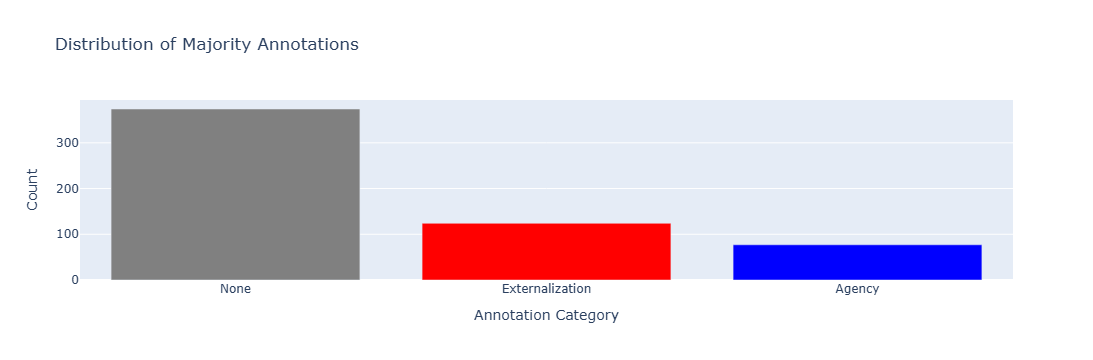

In [40]:
# Count annotations
annotation_counts = (
    majority_df["label"]
    .value_counts()
    .reindex(
        ["none", "externalization", "agency"],
        fill_value=0
    )
)

colors = {
    "none": "grey",
    "externalization": "red",
    "agency": "blue"
}

fig = go.Figure()

fig.add_trace(go.Bar(
    x=["None", "Externalization", "Agency"],
    y=annotation_counts.values,
    marker_color=[
        colors["none"],
        
        colors["externalization"],
        colors["agency"]
    ]
))

fig.update_layout(
    title="Distribution of Majority Annotations",
    xaxis_title="Annotation Category",
    yaxis_title="Count"
)

fig.show()

In [33]:
annotation_counts = majority_df['label'].value_counts()
annotation_counts

label
none               374
externalization    124
agency              77
Name: count, dtype: int64

In [34]:
grouped = majority_df.groupby('label')['token_count'].agg(['mean', 'median', 'std', 'count'])

# Display the descriptive statistics
print(grouped)



                      mean  median        std  count
label                                               
agency           29.558442    26.0  18.655812     77
externalization  23.967742    19.0  20.740728    124
none             17.772727    15.0  13.443326    374


In [35]:
majority_df.to_csv('ground_truth.csv')

### Fleiss' kappa

In [36]:
mapping = {'none': 0, 'agency': 1, 'externalization': 2}


In [37]:
df['label_julian'] = df['label_julian'].map(mapping)
df['label_thea'] = df['label_thea'].map(mapping)
df['label_lisa'] = df['label_lisa'].map(mapping)

In [38]:
df.head()

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,0,0,0,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,1,1,1,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,0,0,0,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,0,0,0,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,1,1,1,38


In [55]:
# Prepare the data for Fleiss' Kappa calculation
annotations = df[['label_julian', 'label_thea', 'label_lisa']]

In [56]:
annotations.head()

,label_julian,label_thea,label_lisa
0,0,0,0
1,1,1,1
2,0,0,0
3,0,0,0
4,1,1,1


In [57]:
# Initialize a DataFrame with zeros for category counts
category_counts = pd.DataFrame(0, index=annotations.index, columns=[0, 1, 2])

In [58]:

for i, row in annotations.iterrows():
    counts = row.value_counts().reindex(range(3), fill_value=0)
    category_counts.loc[i] = counts

In [59]:
if not all(category_counts.sum(axis=1) == len(annotations.columns)):
    raise ValueError("Mismatch in the number of raters per sentence.")

In [60]:
kappa = fleiss_kappa(category_counts.values)

In [45]:
print(f"Fleiss' Kappa: {kappa}")

Fleiss' Kappa: 0.6089043197893904


### Krippendorff's alpha

In [46]:
!pip install krippendorff

You should consider upgrading via the 'c:\users\krusic\appdata\local\programs\python\python39\python.exe -m pip install --upgrade pip' command.


In [47]:
import pandas as pd
import krippendorff

In [48]:
annotations = df[['label_julian', 'label_thea', 'label_lisa']].transpose().values

In [49]:
alpha = krippendorff.alpha(reliability_data=annotations, level_of_measurement='nominal')


In [50]:
print(f"Krippendorff's Alpha: {alpha}")


Krippendorff's Alpha: 0.6091267860466205


### Krippendorf & Kappa 0.6 (moderate)

### Percent agreement - 98 % two-out-of-three, 70 % 3/3

In [51]:
df["agreement"] = (
    (df["label_lisa"] == df["label_julian"]) &
    (df["label_julian"] == df["label_thea"])
)

percent_agreement = df["agreement"].mean() * 100

percent_agreement

70.13651877133105

In [52]:
def calculate_two_out_of_three_agreement_for_all(df):
    # True if at least two of the three annotators agree
    df_with_agreement = df.assign(
        agreement=(
            (df["label_lisa"] == df["label_julian"]) |
            (df["label_julian"] == df["label_thea"]) |
            (df["label_lisa"] == df["label_thea"])
        )
    )

    percent_agreement = df_with_agreement["agreement"].mean() * 100

    return percent_agreement

In [61]:
percent_two_thirds = calculate_two_out_of_three_agreement_for_all(annotations)

print(f"At least 2/3 agreement: {percent_two_thirds:.2f}%")

At least 2/3 agreement: 98.12%
